In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Chargement du Test Set
test_df = pd.read_excel(r"C:\Users\ouard\Smart_Energy_AI\03_Consumption_Prediction\results\test.xlsx")
test_df["Datetime"] = pd.to_datetime(test_df["Datetime"])

# Features utilisées par le modèle
features = [
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

target = "Global_active_power"

X_test = test_df[features]
y_test = test_df[target]

print("Test data loaded successfully.")
print("Test shape:", test_df.shape)

Test data loaded successfully.
Test shape: (525601, 12)


In [5]:
import joblib

gb_model = joblib.load("gradient_boosting_model.pkl")

### Sauvegarde du modèle entraîné

Le modèle Gradient Boosting entraîné est sauvegardé à l'aide de la bibliothèque Joblib. Cette sauvegarde permet de réutiliser le modèle dans le notebook d'analyse et de prédiction, sans devoir effectuer un nouvel entraînement.

In [6]:
import joblib

gb_model = joblib.load("gradient_boosting_model.pkl")

print("Gradient Boosting model loaded successfully.")

Gradient Boosting model loaded successfully.


In [7]:
y_test_pred = gb_model.predict(X_test)

print("Predictions generated successfully.")
print("Number of predictions:", len(y_test_pred))

Predictions generated successfully.
Number of predictions: 525601


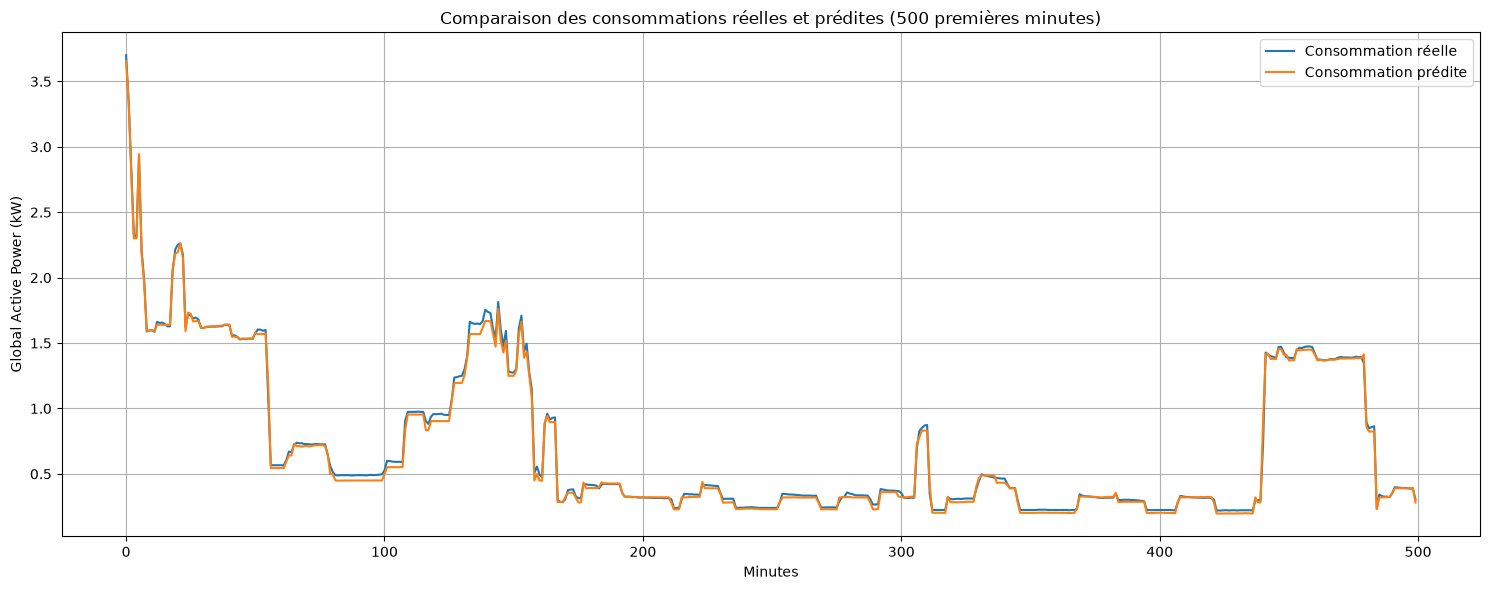

In [8]:
plt.figure(figsize=(15, 6))

plt.plot(y_test.iloc[:500].values, label="Consommation réelle", linewidth=1.5)
plt.plot(y_test_pred[:500], label="Consommation prédite", linewidth=1.5)

plt.title("Comparaison des consommations réelles et prédites (500 premières minutes)")
plt.xlabel("Minutes")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

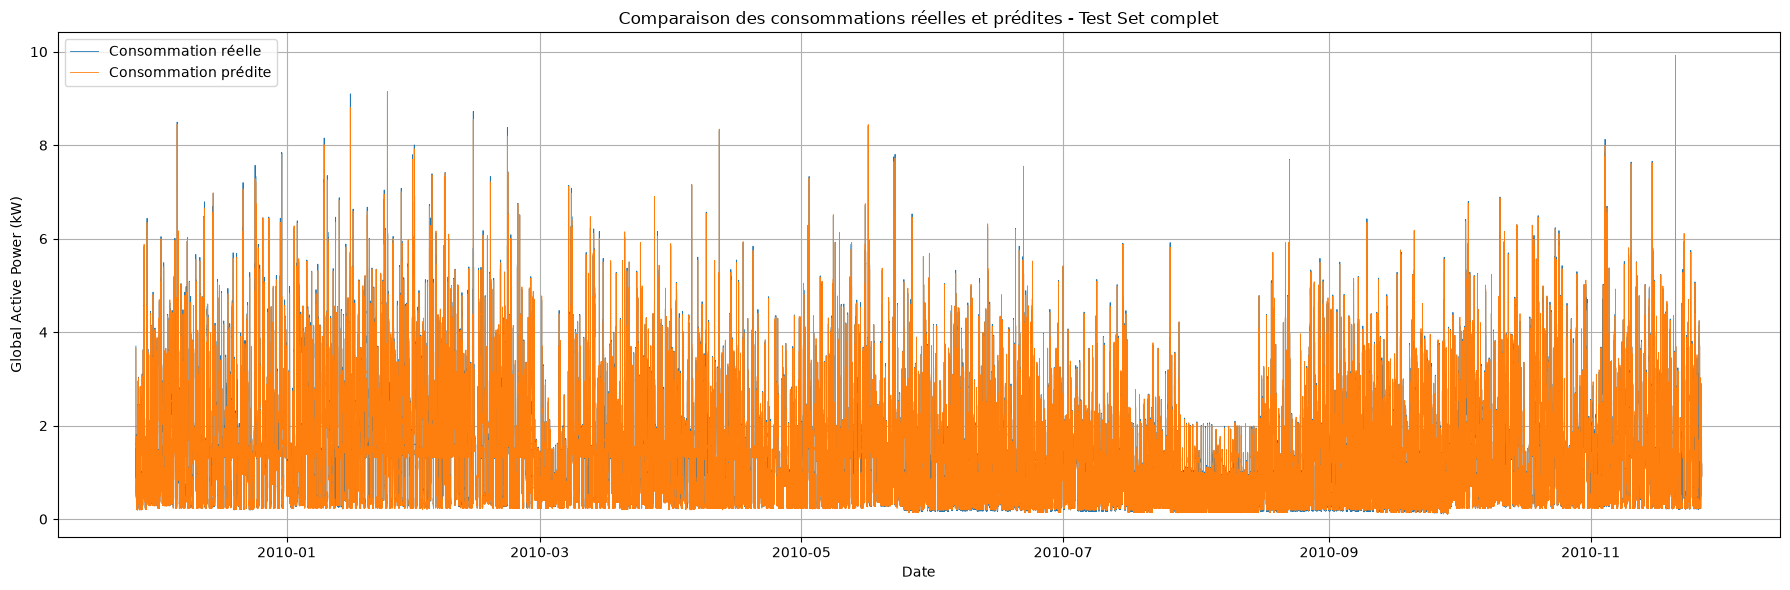

In [9]:
plt.figure(figsize=(18, 6))

plt.plot(test_df["Datetime"], y_test, label="Consommation réelle", linewidth=0.6)
plt.plot(test_df["Datetime"], y_test_pred, label="Consommation prédite", linewidth=0.6)

plt.title("Comparaison des consommations réelles et prédites - Test Set complet")
plt.xlabel("Date")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [10]:
prediction_table = pd.DataFrame({
    "Datetime": test_df["Datetime"],
    "Actual_Consumption": y_test.values,
    "Predicted_Consumption": y_test_pred,
})

prediction_table["Absolute_Error"] = (
    prediction_table["Actual_Consumption"] - 
    prediction_table["Predicted_Consumption"]
).abs()

prediction_table.head()

,Datetime,Actual_Consumption,Predicted_Consumption,Absolute_Error
0,2009-11-26 21:02:00,3.700,3.655635,0.044365
1,2009-11-26 21:03:00,3.348,3.344226,0.003774
2,2009-11-26 21:04:00,2.830,2.792082,0.037918
3,2009-11-26 21:05:00,2.330,2.300375,0.029625
4,2009-11-26 21:06:00,2.308,2.300864,0.007136


In [11]:
prediction_table.to_csv("prediction_results.csv", index=False)

print("Prediction results exported successfully.")

Prediction results exported successfully.
